# Лабораторная работа 1 — рабочий ноутбук

**ФИО:** Гончаренок Андрей Валерьевич
**Файлы данных:** clients.csv , transactions.csv

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

current_dir = os.getcwd()
if current_dir.endswith('notebooks'):
    project_root = os.path.dirname(current_dir)
else:
    project_root = current_dir
clients_path = os.path.join(project_root, 'data', 'clients.csv')
txn_path = os.path.join(project_root, 'data', 'transactions.csv')

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [6]:
try:
    df_clients = pd.read_csv(clients_path, sep=',', encoding='utf-8')
    print(f"\nЗагружено {df_clients.shape[0]} строк и {df_clients.shape[1]} столбцов.")
except UnicodeDecodeError:
    print("\n Ошибка кодировки utf-8.")
    try:
        df_clients = pd.read_csv(clients_path, sep=',', encoding='cp1251')
        print(f"C cp1251! Загружено {df_clients.shape[0]} строк.")
    except Exception as e:
        print(f"Всё равно ошибка: {e}")
except Exception as e:
    print(f"Ошибка при чтении: {e}")
    
if 'df_clients' in locals():
    print("\n--- Первые 5 строки clients.csv ---")
    display(df_clients.head(5))


Загружено 5727 строк и 16 столбцов.

--- Первые 5 строки clients.csv ---


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C004297,1953-08-30,Ж,Новосибирск,Массовый,Базовый,Дебетовая,22.01.2016,25.04.2020,Зарплата в нашем банке,36600.0,Нет,NaN,NaN,453,Нет
1,C004589,1976-03-15,М,Москва,Массовый,Серебро,Кредитная,15.02.2023,13.04.2023,Зарплата в другом банке,66.7,Нет,NaN,4.0,304,Да
2,C005719,1966-12-29,Ж,Санкт-Петербург,Зарплатный,Серебро,Кредитная,10.05.2013,17.08.2017,Зарплата в нашем банке,72900.0,Нет,NaN,NaN,265,Да
3,C005090,1979-03-14,М,Н. Новгород,Массовый,Базовый,Дебетовая,27.09.2017,22.03.2020,Зарплата в нашем банке,63100.0,Нет,NaN,NaN,402,Да
4,C002612,1978-01-10,М,Казань,Массовый,Базовый,Дебетовая,16.12.2015,31.03.2018,Зарплата в нашем банке,109500.0,Нет,NaN,5.0,186,Да


In [7]:
try:
    df_transactions = pd.read_csv(
        txn_path,
        sep=';',
        encoding='cp1251',
        parse_dates=['txn_datetime'],
        na_values=['', 'NA', 'NaN', 'н/д', '-', 'NULL']
    )
    print(f"transactions.csv успешно загружен: {df_transactions.shape[0]} строк, {df_transactions.shape[1]} столбцов")
except Exception as e:
    print(f"Ошибка загрузки transactions.csv: {e}")

if 'df_transactions' in locals():
    print("\n--- Первые 5 строки transactions.csv ---")
    display(df_transactions.head(5))

transactions.csv успешно загружен: 625787 строк, 9 столбцов

--- Первые 5 строки transactions.csv ---


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990050,C004160,2023-12-06,"3890,88",RUB,Продукты,5411,СБП,успешно
1,990154,C001928,2023-12-11 09:07:35,"1474,7",RUB,Продукты,5411,Карта,успешно
2,990039,C003088,2023-12-12,"2713,95",RUB,кафе и рестораны,5812,Токен,успешно
3,990080,C002896,2023-12-17 16:14:28,"2813,66",RUB,Одежда и обувь,5651,Онлайн-банк,успешно
4,990024,C002981,2023-12-25 16:06:15,"22685,69",RUB,Одежда и обувь,5651,Карта,успешно


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [8]:
print("=" * 60)
print("CLIENTS.CSV")
print("=" * 60)
print(f"Размер: {df_clients.shape[0]} строк, {df_clients.shape[1]} столбцов")
print(f"\nЕдиница наблюдения: одна строка = один клиент банка")
print(f"Главный ключ: client_id")

print("\n--- Типы данных, уникальные значения и пропуски ---")
overview_clients = pd.DataFrame({
    'dtype': df_clients.dtypes.astype(str),
    'n_unique': df_clients.nunique(),
    'n_missing': df_clients.isna().sum(),
    'missing_%': (df_clients.isna().mean() * 100).round(2),
})
display(overview_clients)

print("\n" + "=" * 60)
print("TRANSACTIONS.CSV")
print("=" * 60)
print(f"Размер: {df_transactions.shape[0]} строк, {df_transactions.shape[1]} столбцов")
print(f"\nЕдиница наблюдения: одна строка = одна транзакция")
print(f"Главный ключ: txn_id")

print("\n--- Типы данных, уникальные значения и пропуски ---")
overview_txn = pd.DataFrame({
    'dtype': df_transactions.dtypes.astype(str),
    'n_unique': df_transactions.nunique(),
    'n_missing': df_transactions.isna().sum(),
    'missing_%': (df_transactions.isna().mean() * 100).round(2),
})
display(overview_txn)

CLIENTS.CSV
Размер: 5727 строк, 16 столбцов

Единица наблюдения: одна строка = один клиент банка
Главный ключ: client_id

--- Типы данных, уникальные значения и пропуски ---


,dtype,n_unique,n_missing,missing_%
client_id,str,5672,0,0.00
birth_date,str,4820,0,0.00
gender,str,2,0,0.00
city,str,17,0,0.00
segment,str,4,0,0.00
loyalty_tier,str,4,0,0.00
card_type,str,3,0,0.00
registration_date,str,3279,0,0.00
card_open_date,str,2646,0,0.00
income_source,str,3,0,0.00



TRANSACTIONS.CSV
Размер: 625787 строк, 9 столбцов

Единица наблюдения: одна строка = одна транзакция
Главный ключ: txn_id

--- Типы данных, уникальные значения и пропуски ---


,dtype,n_unique,n_missing,missing_%
txn_id,int64,624287,0,0.0
client_id,str,5985,0,0.0
txn_datetime,str,568882,0,0.0
amount,str,321452,0,0.0
currency,str,3,0,0.0
category,str,12,0,0.0
mcc_code,int64,9,0,0.0
channel,str,4,0,0.0
status,str,3,0,0.0


### 2.2. Дубли

In [9]:
print("=" * 60)
print("ПРОВЕРКА ДУБЛИКАТОВ")
print("=" * 60)

# --- clients ---
print("\n--- clients.csv ---")
print(f"Всего строк: {len(df_clients)}")
print(f"Уникальных client_id: {df_clients['client_id'].nunique()}")
print(f"Дубликатов client_id: {df_clients['client_id'].duplicated().sum()}")
print(f"Полных дубликатов строк (все столбцы совпадают): {df_clients.duplicated().sum()}")

# Примеры дубликатов
client_dups = df_clients[df_clients['client_id'].duplicated(keep=False)]
if len(client_dups) > 0:
    print(f"\nПримеры дубликатов (первые 10 строк):")
    display(client_dups.sort_values('client_id').head(10))

# --- transactions ---
print("\n--- transactions.csv ---")
print(f"Всего строк: {len(df_transactions)}")
print(f"Уникальных txn_id: {df_transactions['txn_id'].nunique()}")
print(f"Дубликатов txn_id: {df_transactions['txn_id'].duplicated().sum()}")
print(f"Полных дубликатов строк: {df_transactions.duplicated().sum()}")

txn_dups = df_transactions[df_transactions['txn_id'].duplicated(keep=False)]
if len(txn_dups) > 0:
    print(f"\nПримеры дубликатов (первые 10 строк):")
    display(txn_dups.sort_values('txn_id').head(10))

ПРОВЕРКА ДУБЛИКАТОВ

--- clients.csv ---
Всего строк: 5727
Уникальных client_id: 5672
Дубликатов client_id: 55
Полных дубликатов строк (все столбцы совпадают): 41

Примеры дубликатов (первые 10 строк):


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
3194,C000034,1976-10-21,Ж,Екатеринбург,Массовый,Базовый,Кредитная,15.03.2015,21.03.2017,Зарплата в нашем банке,49100.0,Да,2024-09,2.0,553,Да
3878,C000034,1976-10-21,Ж,казань,Массовый,Базовый,Кредитная,15.03.2015,21.03.2017,Зарплата в нашем банке,49100.0,Да,2024-09,2.0,553,Да
1000,C000080,1989-05-16,М,МОСКВА,Массовый,Базовый,Дебетовая,26.07.2013,28.02.2017,Зарплата в нашем банке,NaN,Да,2025-05,NaN,248,Да
3769,C000080,1989-05-16,М,МОСКВА,Массовый,Базовый,Дебетовая,26.07.2013,28.02.2017,Зарплата в нашем банке,NaN,Да,2025-05,NaN,248,Да
3210,C000097,1951-12-31,М,казань,Массовый,Серебро,Кредитная,18.08.2014,14.09.2019,Зарплата в другом банке,70400.0,Нет,NaN,NaN,324,Да
5129,C000097,1951-12-31,М,казань,Массовый,Серебро,Кредитная,18.08.2014,14.09.2019,Зарплата в другом банке,70400.0,Нет,NaN,NaN,324,Да
15,C000249,1988-10-31,Ж,Москва,Премиальный,Золото,Кредитная,10.02.2022,05.10.2023,Зарплата в другом банке,185200.0,Да,2024-12,NaN,693,Да
339,C000249,1988-10-31,Ж,Москва,Премиальный,Золото,Кредитная,10.02.2022,05.10.2023,Зарплата в другом банке,185200.0,Да,2024-12,NaN,693,Да
788,C000317,1956-01-29,Ж,г. Санкт-Петербург,Массовый,Базовый,Дебетовая,06.12.2014,08.07.2020,Зарплата в нашем банке,69700.0,Да,2024-10,1.0,852,Да
4052,C000317,1956-01-29,Ж,г. Санкт-Петербург,Массовый,Базовый,Дебетовая,06.12.2014,08.07.2020,Зарплата в нашем банке,69700.0,Да,2024-10,1.0,852,Да



--- transactions.csv ---
Всего строк: 625787
Уникальных txn_id: 624287
Дубликатов txn_id: 1500
Полных дубликатов строк: 1284

Примеры дубликатов (первые 10 строк):


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
96,100090,C002052,2024-01-01 09:11:12,"1668,8",RUB,Продукты,5411,Карта,успешно
97,100090,C002052,2024-01-01 09:11:12,"1668,8",RUB,Продукты,5411,Карта,успешно
338,100331,C005416,2024-01-01 13:50:47,"588,24",RUB,Продукты,5411,СБП,успешно
339,100331,C005416,2024-01-01 13:50:47,"588,24",RUB,Продукты,5411,СБП,успешно
451,100443,C000105,2024-01-01 15:29:44,"2475,73",RUB,АЗС,5541,Карта,успешно
452,100443,C000105,2024-01-01 15:29:44,"2475,73",RUB,АЗС,5541,Карта,успешно
798,100789,C003992,2024-01-02 08:37:31,"1609,31",RUB,Продукты,5411,Онлайн-банк,успешно
799,100789,C003992,2024-01-02 08:37:31,"1609,31",RUB,Продукты,5411,Онлайн-банк,успешно
1108,101098,C001108,2024-01-02 13:54:08,"125,68",RUB,Транспорт,4111,Карта,успешно
1109,101098,C001108,2024-01-02 13:54:08,"125,68",RUB,Транспорт,4111,Карта,успешно


### 2.3. Соответствие данных описанию полей из задания

In [10]:
print("=" * 70)
print("ПРОВЕРКА СООТВЕТСТВИЯ ДАННЫХ ОПИСАНИЮ ИЗ TASK.md")
print("=" * 70)

# transactions.csv
print("\n--- transactions.csv ---")

# Проверка category на соответствие описанию "одна из девяти"
print("\n1. Поле 'category' (в описании: 'категория траты, одна из девяти'):")
n_cat = df_transactions['category'].nunique()
print(f"   Фактическое количество уникальных значений: {n_cat}")
print(f"   Значения: {df_transactions['category'].unique()}")
if n_cat != 9:
    print(f"   РАСХОЖДЕНИЕ: в описании указано 9, фактически найдено {n_cat} категорий.")
else:
    print("   Соответствует описанию.")

# Проверка channel на соответствие описанию (4 значения)
print("\n2. Поле 'channel' (в описании: 'Карта, Токен, СБП, Онлайн-банк'):")
n_ch = df_transactions['channel'].nunique()
print(f"   Фактическое количество уникальных значений: {n_ch}")
print(f"   Значения: {df_transactions['channel'].unique()}")
if n_ch == 4:
    print("   Соответствует описанию.")
else:
    print(f"   РАСХОЖДЕНИЕ: ожидалось 4 значения, найдено {n_ch}.")

# Проверка status на соответствие описанию (3 значения)
print("\n3. Поле 'status' (в описании: 'успешно, отклонено, возврат'):")
n_st = df_transactions['status'].nunique()
print(f"   Фактическое количество уникальных значений: {n_st}")
print(f"   Значения: {df_transactions['status'].unique()}")
if n_st == 3:
    print("   Соответствует описанию.")
else:
    print(f"   РАСХОЖДЕНИЕ: ожидалось 3 значения, найдено {n_st}.")

# clients.csv
print("\n--- clients.csv ---")

# Проверка satisfaction_score на диапазон [1, 5]
print("\n4. Поле 'satisfaction_score' (в описании: 'оценка от 1 до 5'):")
print(f"   Минимум: {df_clients['satisfaction_score'].min()}")
print(f"   Максимум: {df_clients['satisfaction_score'].max()}")
if df_clients['satisfaction_score'].min() < 1 or df_clients['satisfaction_score'].max() > 5:
    print("   НАРУШЕНИЕ ВАЛИДНОСТИ: значения выходят за диапазон [1, 5].")
else:
    print("   Соответствует описанию.")

# Проверка branch_code на неотрицательность
print("\n5. Поле 'branch_code' (в описании: 'код отделения обслуживания'):")
print(f"   Минимум: {df_clients['branch_code'].min()}")
print(f"   Максимум: {df_clients['branch_code'].max()}")
if df_clients['branch_code'].min() < 0:
    print("   НАРУШЕНИЕ ВАЛИДНОСТИ: найдены отрицательные коды.")
else:
    print("   Соответствует описанию.")

# Проверка monthly_income на скрытые пропуски (отрицательные значения)
print("\n6. Поле 'monthly_income' (в описании: 'ежемесячный доход, рублей'):")
min_income = df_clients['monthly_income'].min()
print(f"   Минимальное значение: {min_income}")
if min_income < 0:
    print(f"   НАРУШЕНИЕ ВАЛИДНОСТИ: найдено отрицательное значение {min_income} (вероятно, технический код пропуска).")

# Проверка city на согласованность регистра
print("\n7. Поле 'city' (в описании: 'город проживания'):")
n_cities = df_clients['city'].nunique()
n_cities_lower = df_clients['city'].str.lower().nunique()
print(f"   Уникальных значений с учётом регистра: {n_cities}")
print(f"   Уникальных значений без учёта регистра: {n_cities_lower}")
if n_cities > n_cities_lower:
    print(f"   НАРУШЕНИЕ СОГЛАСОВАННОСТИ: есть города с разным регистром (например, 'Москва' и 'москва').")
    # Примеры пар с разным регистром
    city_counts = df_clients['city'].str.lower().value_counts()
    ambiguous = city_counts[city_counts > 1].index.tolist()
    print(f"   Города, встречающиеся в разных регистрах: {ambiguous[:5]}")
else:
    print("   Согласованность регистра соблюдена.")

# Итог
print("\n" + "=" * 70)
print("ИТОГОВЫЙ СПИСОК РАСХОЖДЕНИЙ")
print("=" * 70)
print("""
1. transactions.csv, поле 'category': описание указывает 9 категорий,
   фактически найдено 12 уникальных значений.

2. clients.csv, поле 'monthly_income': найдено значение -999,
   что является скрытым пропуском (доход не может быть отрицательным).

3. clients.csv, поле 'city': нарушена согласованность регистра
   (например, 'Москва' и 'москва'), что завышает число уникальных значений.
""")

ПРОВЕРКА СООТВЕТСТВИЯ ДАННЫХ ОПИСАНИЮ ИЗ TASK.md

--- transactions.csv ---

1. Поле 'category' (в описании: 'категория траты, одна из девяти'):
   Фактическое количество уникальных значений: 12
   Значения: <ArrowStringArray>
[           'Продукты',    'кафе и рестораны',      'Одежда и обувь',
              'Аптеки',           'Транспорт',    'Связь и интернет',
      'Онлайн-сервисы',                 'АЗС', 'Развлечения и досуг',
    'Кафе и рестораны',      'Кафе/рестораны',    'Связь и Интернет']
Length: 12, dtype: str
   РАСХОЖДЕНИЕ: в описании указано 9, фактически найдено 12 категорий.

2. Поле 'channel' (в описании: 'Карта, Токен, СБП, Онлайн-банк'):
   Фактическое количество уникальных значений: 4
   Значения: <ArrowStringArray>
['СБП', 'Карта', 'Токен', 'Онлайн-банк']
Length: 4, dtype: str
   Соответствует описанию.

3. Поле 'status' (в описании: 'успешно, отклонено, возврат'):
   Фактическое количество уникальных значений: 3
   Значения: <ArrowStringArray>
['успешно', 'откло

### 2.4. Связь между таблицами

In [11]:
print("=" * 60)
print("СВЯЗЬ МЕЖДУ TABLES")
print("=" * 60)

# все ли client_id из transactions есть в clients
clients_ids = set(df_clients['client_id'].unique())
txn_ids = set(df_transactions['client_id'].unique())

print(f"\nУникальных клиентов в clients.csv: {len(clients_ids)}")
print(f"Уникальных клиентов в transactions.csv: {len(txn_ids)}")

# Клиенты из транзакций, которых нет в справочнике клиентов
missing_in_clients = txn_ids - clients_ids
print(f"\nКлиентов в транзакциях, но НЕ в clients.csv: {len(missing_in_clients)}")
if len(missing_in_clients) > 0:
    print(f"Примеры: {list(missing_in_clients)[:10]}")

# Клиенты из справочника без транзакций
missing_in_txn = clients_ids - txn_ids
print(f"\nКлиентов в clients.csv, но БЕЗ транзакций: {len(missing_in_txn)}")
if len(missing_in_txn) > 0:
    print(f"Примеры: {list(missing_in_txn)[:10]}")

# Кардинальность связи
print("\n--- Кардинальность связи ---")
txn_per_client = df_transactions.groupby('client_id').size()
print(f"Транзакций на клиента:")
print(f"  Минимум: {txn_per_client.min()}")
print(f"  Максимум: {txn_per_client.max()}")
print(f"  Медиана: {txn_per_client.median()}")
print(f"  Среднее: {txn_per_client.mean():.1f}")

# Распределение числа транзакций
print(f"\nРаспределение числа транзакций на клиента:")
print(txn_per_client.describe())

СВЯЗЬ МЕЖДУ TABLES

Уникальных клиентов в clients.csv: 5672
Уникальных клиентов в transactions.csv: 5985

Клиентов в транзакциях, но НЕ в clients.csv: 328
Примеры: ['C002305', 'C000664', 'C004555', 'C000953', 'C000424', 'C004866', 'C001145', 'C004640', 'C003761', 'C000980']

Клиентов в clients.csv, но БЕЗ транзакций: 15
Примеры: ['C000710', 'C000415', 'C003062', 'C001233', 'C001628', 'C005669', 'C000538', 'C001169', 'C004002', 'C004339']

--- Кардинальность связи ---
Транзакций на клиента:
  Минимум: 1
  Максимум: 740
  Медиана: 89.0
  Среднее: 104.6

Распределение числа транзакций на клиента:
count    5985.000000
mean      104.559231
std        78.842009
min         1.000000
25%        52.000000
50%        89.000000
75%       140.000000
max       740.000000
dtype: float64


**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

# Выводы по аудиту качества данных

## 1. clients.csv (5727 строк × 16 столбцов)

### 1.1. Дубликаты
Обнаружено **55 дубликатов** по полю `client_id` (из 5727 строк уникальных ID — 5672). Из них **41 строка** является полным дубликатом (совпадают все 16 полей). Это нарушает критерий уникальности.

### 1.2. Невалидные значения и скрытые пропуски
- `monthly_income`: минимум **-999.0**. Это не реальный доход, а технический код пропуска (скрытый пропуск), который необходимо заменить на `NaN`.
- `satisfaction_score` и `branch_code`: диапазоны корректны (1.0–5.0 и 100–939 соответственно), невалидных значений не обнаружено.

### 1.3. Несоответствие типов
- Колонки `birth_date`, `registration_date`, `card_open_date` имеют тип `str` (object) вместо ожидаемого `datetime64`. Это делает невозможным расчёт возраста клиента и стажа.

### 1.4. Проблемы согласованности
- В поле `city` встречаются значения с разным регистром (например, `'Москва'` и `'москва'`). Это искусственно раздувает число уникальных значений.

### 1.5. Пропуски
| Поле | Пропусков | Доля | Вероятный механизм |
|------|-----------|------|---------------------|
| `monthly_income` | 559 | 9.76% | MAR (не указывают клиенты с нестабильным доходом) |
| `app_last_login` | 2187 | 38.19% | MAR (отсутствует у клиентов без приложения) |
| `satisfaction_score` | 3463 | 60.47% | MAR/MNAR (опрос проходят только активные клиенты) |

---

## 2. transactions.csv (625 787 строк × 9 столбцов)

### 2.1. Дубликаты
Обнаружено **1500 дубликатов** по полю `txn_id` (из 625 787 строк уникальных — 624 287). Из них **1284 строки** — полные дубликаты.

### 2.2. Несоответствие типов
| Поле | Текущий тип | Ожидаемый | Проблема |
|------|-------------|-----------|----------|
| `txn_id` | `int64` | `string` | Риск потери ведущих нулей, ошибки при merge |
| `txn_datetime` | `str` | `datetime64` | Невозможны временные операции |
| `amount` | `str` | `float64` | Невозможны математические операции (суммирование) |
| `category`, `channel`, `status`, `currency`, `mcc_code` | `str` / `int64` | `category` | Неэффективно по памяти (мало уникальных значений) |

### 2.3. Расхождения с описанием из TASK.md и нарушения валидности

При сверке фактических данных с описанием из `TASK.md` выявлены следующие расхождения:

1. **transactions.csv, поле `category`**: в описании указано "одна из девяти" категорий, но фактически в данных присутствует **12 уникальных значений**. Это требует дополнительного маппинга или уточнения у владельца данных.
2. **clients.csv, поле `monthly_income`**: обнаружено отрицательное значение (минимум **-999**). Доход не может быть отрицательным, следовательно, это **скрытый пропуск** (технический код), который необходимо заменить на `NaN`.
3. **clients.csv, поле `city`**: нарушена согласованность формата. Встречаются названия городов с разным регистром (например, `'Москва'` и `'москва'`), что искусственно завышает количество уникальных значений.

*Примечание: поля `channel` и `status` в транзакциях полностью соответствуют описанию (4 и 3 уникальных значения соответственно).*

### 2.4. Пропуски
Отсутствуют (полнота 100%), что соответствует ожиданиям для процессинговой системы.

---

## 3. Связь между таблицами
- **328 клиентов** присутствуют в транзакциях, но отсутствуют в справочнике `clients.csv` (при `INNER JOIN` эти строки потеряются).
- **15 клиентов** есть в справочнике, но не имеют ни одной транзакции.
- Связь **one-to-many**: в среднем 104.6 транзакций на клиента (медиана — 89).

---

## 4. Итоговый план для раздела «Препроцессинг»
1. Удалить дубликаты по `client_id` и `txn_id`.
2. Конвертировать типы: даты в `datetime64`, `amount` в `float64`, `txn_id` в `string`, категориальные признаки в `category`.
3. Заменить `-999` в `monthly_income` на `NaN`.
4. Привести `city` к единому регистру (например, заглавная первая буква).
5. Обработать пропуски в `monthly_income`, `app_last_login` и `satisfaction_score` (с проверкой гипотез о механизме пропусков).

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

In [12]:
df_clients_clean = df_clients.copy()
df_transactions_clean = df_transactions.copy()

print(f"Исходные данные: clients {df_clients_clean.shape}, transactions {df_transactions_clean.shape}")

# Список для накопления записей журнала
cleaning_log_list = []

def log_change(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    cleaning_log_list.append({
        'field': field,
        'issue': issue,
        'scope': scope,
        'n_rows': n_rows,
        'value_before': value_before,
        'action': action,
        'value_after': value_after,
        'rationale': rationale,
    })

Исходные данные: clients (5727, 16), transactions (625787, 9)


### 3.1. Типы, даты, числа

In [13]:
print("=" * 70)
print("3.1. КОНВЕРТАЦИЯ ТИПОВ")
print("=" * 70)

# --- clients.csv ---
print("\n--- clients.csv ---")

# Даты: birth_date (ISO), registration_date и card_open_date (ДД.ММ.ГГГГ)
df_clients_clean['birth_date'] = pd.to_datetime(
    df_clients_clean['birth_date'], errors='coerce'
)
df_clients_clean['registration_date'] = pd.to_datetime(
    df_clients_clean['registration_date'], dayfirst=True, errors='coerce'
)
df_clients_clean['card_open_date'] = pd.to_datetime(
    df_clients_clean['card_open_date'], dayfirst=True, errors='coerce'
)

# Скрытый пропуск в monthly_income: значение -999 заменяется на NaN
n_negative_income = (df_clients_clean['monthly_income'] < 0).sum()
df_clients_clean.loc[df_clients_clean['monthly_income'] < 0, 'monthly_income'] = np.nan

# Идентификатор приводится к типу string для консистентности
df_clients_clean['client_id'] = df_clients_clean['client_id'].astype('string')

print(f"Даты конвертированы: birth_date, registration_date, card_open_date")
print(f"Отрицательных значений monthly_income заменено на NaN: {n_negative_income}")

# --- transactions.csv ---
print("\n--- transactions.csv ---")

# txn_id: int64 -> string (идентификатор, не число)
df_transactions_clean['txn_id'] = df_transactions_clean['txn_id'].astype('string')
df_transactions_clean['client_id'] = df_transactions_clean['client_id'].astype('string')

# txn_datetime: str -> datetime64
# Даты в смешанном формате: часть только дата, часть дата+время
# Пробуем гибкий парсинг
df_transactions_clean['txn_datetime'] = pd.to_datetime(
    df_transactions['txn_datetime'],  # Берём из ИСХОДНОГО DataFrame
    format='mixed',
    errors='coerce'
)

# Проверяем результат
n_parsed = df_transactions_clean['txn_datetime'].notna().sum()
n_total = len(df_transactions_clean)
print(f"Распознано дат: {n_parsed} из {n_total} ({n_parsed/n_total*100:.1f}%)")
print(f"Пропусков (NaT): {df_transactions_clean['txn_datetime'].isna().sum()}")

# amount: str -> float64. Числа в европейском формате (запятая как десятичный разделитель)
df_transactions_clean['amount'] = (
    df_transactions_clean['amount']
    .astype(str)
    .str.replace(' ', '', regex=False)
    .str.replace(',', '.', regex=False)
)
df_transactions_clean['amount'] = pd.to_numeric(
    df_transactions_clean['amount'], errors='coerce'
)

print(f"txn_id, client_id конвертированы в string")
print(f"txn_datetime конвертирована в datetime64")
print(f"amount конвертирована в float64")

# --- Проверка результатов ---
print("\n--- Итоговые типы данных ---")
print("\nclients.csv:")
print(df_clients_clean[['birth_date', 'registration_date', 'card_open_date', 
                        'monthly_income', 'client_id']].dtypes.to_frame('dtype'))

print("\ntransactions.csv:")
print(df_transactions_clean[['txn_id', 'client_id', 'txn_datetime', 'amount']].dtypes.to_frame('dtype'))

# --- Пропуски после конвертации ---
print("\n--- Пропуски после конвертации ---")
print("\nclients.csv (даты и monthly_income):")
print(df_clients_clean[['birth_date', 'registration_date', 'card_open_date', 
                        'monthly_income']].isna().sum())

print("\ntransactions.csv (txn_datetime и amount):")
print(df_transactions_clean[['txn_datetime', 'amount']].isna().sum())

# --- Запись в журнал ---
log_change(
    field='birth_date, registration_date, card_open_date',
    issue='тип str вместо datetime64',
    scope='clients',
    n_rows=len(df_clients_clean),
    value_before='str',
    action="pd.to_datetime(errors='coerce')",
    value_after='datetime64[ns]',
    rationale='Необходимо для расчёта возраста клиента, стажа и срока обслуживания.'
)

log_change(
    field='monthly_income',
    issue='скрытый пропуск -999',
    scope='clients',
    n_rows=n_negative_income,
    value_before='-999',
    action='замена на NaN',
    value_after='NaN',
    rationale='Доход не может быть отрицательным. Значение -999 является техническим кодом пропуска.'
)

log_change(
    field='client_id',
    issue='явное приведение к string',
    scope='clients',
    n_rows=len(df_clients_clean),
    value_before='str',
    action="astype('string')",
    value_after='string',
    rationale='Консистентность типов для последующего merge с transactions.'
)

log_change(
    field='txn_id, client_id',
    issue='txn_id как int64, client_id как str',
    scope='transactions',
    n_rows=len(df_transactions_clean),
    value_before='int64 / str',
    action="astype('string')",
    value_after='string',
    rationale='Идентификаторы не участвуют в математических операциях. Предотвращает потерю ведущих нулей и ошибки при merge.'
)

log_change(
    field='txn_datetime',
    issue='тип str вместо datetime64',
    scope='transactions',
    n_rows=len(df_transactions_clean),
    value_before='str',
    action="pd.to_datetime(errors='coerce')",
    value_after='datetime64[ns]',
    rationale='Необходимо для временных операций: группировка по месяцам, расчёт интервалов.'
)

log_change(
    field='amount',
    issue='тип str вместо float64, европейский формат с запятой',
    scope='transactions',
    n_rows=len(df_transactions_clean),
    value_before='str',
    action="str.replace(',', '.') + pd.to_numeric(errors='coerce')",
    value_after='float64',
    rationale='Необходимо для математических операций: суммирование оборотов, расчёт статистики.'
)

print(f"\nЗаписей в журнале после 3.1: {len(cleaning_log_list)}")

3.1. КОНВЕРТАЦИЯ ТИПОВ

--- clients.csv ---
Даты конвертированы: birth_date, registration_date, card_open_date
Отрицательных значений monthly_income заменено на NaN: 55

--- transactions.csv ---
Распознано дат: 625787 из 625787 (100.0%)
Пропусков (NaT): 0
txn_id, client_id конвертированы в string
txn_datetime конвертирована в datetime64
amount конвертирована в float64

--- Итоговые типы данных ---

clients.csv:
                            dtype
birth_date         datetime64[us]
registration_date  datetime64[us]
card_open_date     datetime64[us]
monthly_income            float64
client_id                  string

transactions.csv:
                       dtype
txn_id                string
client_id             string
txn_datetime  datetime64[us]
amount               float64

--- Пропуски после конвертации ---

clients.csv (даты и monthly_income):
birth_date             0
registration_date      0
card_open_date         0
monthly_income       614
dtype: int64

transactions.csv (txn_datetim

### 3.2. Категориальные признаки

In [14]:
print("=" * 70)
print("3.2. КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ")
print("=" * 70)

# --- clients.csv ---
print("\n--- clients.csv ---")

# Нормализация названий городов
# 1. Автоматическое удаление префиксов и нормализация пробелов
n_city_before = df_clients_clean['city'].nunique()

df_clients_clean['city'] = (
    df_clients_clean['city']
    .str.strip()
    .str.replace(r'^г\.\s*', '', regex=True, case=False)
    .str.replace(r'^город\s+', '', regex=True, case=False)
    .str.replace(r'\s+', ' ', regex=True)
    .str.title()
)

# 2. Маппинг для специфических аномалий
city_mapping = {
    'Санкт Петербург': 'Санкт-Петербург',
    'Н. Новгород': 'Нижний Новгород',
    'Спб': 'Санкт-Петербург',
}
df_clients_clean['city'] = df_clients_clean['city'].replace(city_mapping)

n_city_after = df_clients_clean['city'].nunique()

print(f"Уникальных значений city до нормализации: {n_city_before}")
print(f"Уникальных значений city после нормализации: {n_city_after}")
print(f"Значения city: {df_clients_clean['city'].unique()}")

# Конвертация категориальных признаков в тип category
clients_cat_cols = [
    'gender', 'city', 'segment', 'loyalty_tier', 
    'card_type', 'income_source', 'has_mobile_app', 'marketing_opt_in'
]

for col in clients_cat_cols:
    df_clients_clean[col] = df_clients_clean[col].astype('category')

print(f"\nКатегориальные признаки конвертированы: {clients_cat_cols}")

# --- transactions.csv ---
print("\n--- transactions.csv ---")

# Конвертация категориальных признаков в тип category
txn_cat_cols = ['currency', 'category', 'channel', 'status', 'mcc_code']

for col in txn_cat_cols:
    df_transactions_clean[col] = df_transactions_clean[col].astype('category')

print(f"Категориальные признаки конвертированы: {txn_cat_cols}")

# --- Проверка результатов ---
print("\n--- Итоговые типы данных ---")
print("\nclients.csv (категориальные):")
print(df_clients_clean[clients_cat_cols].dtypes.to_frame('dtype'))

print("\ntransactions.csv (категориальные):")
print(df_transactions_clean[txn_cat_cols].dtypes.to_frame('dtype'))

# --- Проверка экономии памяти ---
mem_clients_before = df_clients[clients_cat_cols].memory_usage(deep=True).sum() / 1024**2
mem_clients_after = df_clients_clean[clients_cat_cols].memory_usage(deep=True).sum() / 1024**2

mem_txn_before = df_transactions[txn_cat_cols].memory_usage(deep=True).sum() / 1024**2
mem_txn_after = df_transactions_clean[txn_cat_cols].memory_usage(deep=True).sum() / 1024**2

print(f"\n--- Экономия памяти ---")
print(f"clients: {mem_clients_before:.2f} МБ -> {mem_clients_after:.2f} МБ (экономия: {(mem_clients_before - mem_clients_after):.2f} МБ)")
print(f"transactions: {mem_txn_before:.2f} МБ -> {mem_txn_after:.2f} МБ (экономия: {(mem_txn_before - mem_txn_after):.2f} МБ)")

# --- Запись в журнал ---
log_change(
    field='city',
    issue='нарушение согласованности регистра и префиксы',
    scope='clients',
    n_rows=len(df_clients_clean),
    value_before=f'{n_city_before} уникальных значений (разный регистр, префиксы "г.", сокращения)',
    action='regex-очистка префиксов + маппинг аномалий',
    value_after=f'{n_city_after} уникальных значений',
    rationale='Приведение к единому формату для корректной агрегации по городам.'
)

log_change(
    field='gender, city, segment, loyalty_tier, card_type, income_source, has_mobile_app, marketing_opt_in',
    issue='тип str вместо category',
    scope='clients',
    n_rows=len(df_clients_clean),
    value_before='str',
    action="astype('category')",
    value_after='category',
    rationale='Признаки имеют мало уникальных значений. Тип category экономит память и ускоряет группировки.'
)

log_change(
    field='currency, category, channel, status, mcc_code',
    issue='тип str/int64 вместо category',
    scope='transactions',
    n_rows=len(df_transactions_clean),
    value_before='str/int64',
    action="astype('category')",
    value_after='category',
    rationale='Признаки имеют мало уникальных значений (3-12). Тип category экономит память и ускоряет группировки. mcc_code — код категории торговой точки, а не число.'
)

print(f"\nЗаписей в журнале после 3.2: {len(cleaning_log_list)}")

3.2. КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ

--- clients.csv ---
Уникальных значений city до нормализации: 17
Уникальных значений city после нормализации: 6
Значения city: <ArrowStringArray>
[    'Новосибирск',          'Москва', 'Санкт-Петербург', 'Нижний Новгород',
          'Казань',    'Екатеринбург']
Length: 6, dtype: str

Категориальные признаки конвертированы: ['gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'income_source', 'has_mobile_app', 'marketing_opt_in']

--- transactions.csv ---
Категориальные признаки конвертированы: ['currency', 'category', 'channel', 'status', 'mcc_code']

--- Итоговые типы данных ---

clients.csv (категориальные):
                     dtype
gender            category
city              category
segment           category
loyalty_tier      category
card_type         category
income_source     category
has_mobile_app    category
marketing_opt_in  category

transactions.csv (категориальные):
             dtype
currency  category
category  category
channel   

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [15]:
print("=" * 70)
print("3.3. ОБРАБОТКА ПРОПУСКОВ")
print("=" * 70)

# --- 1. monthly_income (заполнение медианой по сегменту) ---
print("\n--- monthly_income ---")
missing_income_before = df_clients_clean['monthly_income'].isna().sum()
print(f"Пропусков до обработки: {missing_income_before}")

# Заполнение медианой внутри каждого сегмента
df_clients_clean['monthly_income'] = df_clients_clean.groupby('segment')['monthly_income'].transform(
    lambda x: x.fillna(x.median())
)

missing_income_after = df_clients_clean['monthly_income'].isna().sum()
print(f"Пропусков после обработки: {missing_income_after}")

log_change(
    field='monthly_income',
    issue='пропуски (MAR)',
    scope='clients',
    n_rows=missing_income_before,
    value_before=f'{missing_income_before} NaN',
    action='заполнение медианой в разрезе segment',
    value_after=f'{missing_income_after} NaN',
    rationale='Доход зависит от сегмента клиента. Заполнение общей медианой исказило бы распределение.'
)

# --- 2. app_last_login (оставление как есть) ---
print("\n--- app_last_login ---")
missing_app_login = df_clients_clean['app_last_login'].isna().sum()
print(f"Пропусков: {missing_app_login} ({missing_app_login/len(df_clients_clean)*100:.1f}%)")
print("Решение: пропуски оставлены без изменений.")

log_change(
    field='app_last_login',
    issue='пропуски (MAR)',
    scope='clients',
    n_rows=missing_app_login,
    value_before=f'{missing_app_login} NaN',
    action='оставлено как есть',
    value_after=f'{missing_app_login} NaN',
    rationale='Пропуск логически обусловлен отсутствием мобильного приложения (has_mobile_app = Нет). Заполнение исказит данные.'
)

# --- 3. satisfaction_score (создание индикатора, пропуски не заполняются) ---
print("\n--- satisfaction_score ---")
missing_sat_before = df_clients_clean['satisfaction_score'].isna().sum()
print(f"Пропусков до обработки: {missing_sat_before} ({missing_sat_before/len(df_clients_clean)*100:.1f}%)")

# Создание бинарного индикатора: 1, если оценка есть, 0, если пропуск
df_clients_clean['has_satisfaction_score'] = df_clients_clean['satisfaction_score'].notna().astype(int)

missing_sat_after = df_clients_clean['satisfaction_score'].isna().sum()
print(f"Пропусков в исходном поле после обработки: {missing_sat_after}")
print("Создан новый признак: has_satisfaction_score")

log_change(
    field='satisfaction_score',
    issue='пропуски (MAR/MNAR, >60%)',
    scope='clients',
    n_rows=missing_sat_before,
    value_before=f'{missing_sat_before} NaN',
    action='создание индикатора has_satisfaction_score, пропуски не заполнены',
    value_after=f'{missing_sat_after} NaN + новый признак',
    rationale='Доля пропусков слишком высока для надежной импутации. Сам факт отсутствия оценки может быть информативным.'
)

# --- 4. Проверка остальных полей ---
print("\n--- Проверка остальных полей ---")
print("Пропуски в датах clients:", df_clients_clean[['birth_date', 'registration_date', 'card_open_date']].isna().sum().sum())
print("Пропуски в txn_datetime:", df_transactions_clean['txn_datetime'].isna().sum())
print("Пропуски в amount:", df_transactions_clean['amount'].isna().sum())

print(f"\nЗаписей в журнале после 3.3: {len(cleaning_log_list)}")

3.3. ОБРАБОТКА ПРОПУСКОВ

--- monthly_income ---
Пропусков до обработки: 614
Пропусков после обработки: 0

--- app_last_login ---
Пропусков: 2187 (38.2%)
Решение: пропуски оставлены без изменений.

--- satisfaction_score ---
Пропусков до обработки: 3463 (60.5%)
Пропусков в исходном поле после обработки: 3463
Создан новый признак: has_satisfaction_score

--- Проверка остальных полей ---
Пропуски в датах clients: 0
Пропуски в txn_datetime: 0
Пропуски в amount: 0

Записей в журнале после 3.3: 12


### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [16]:
print("=" * 70)
print("3.4. ОБНАРУЖЕНИЕ И ОБРАБОТКА ВЫБРОСОВ")
print("=" * 70)

import numpy as np

# --- 1. Выбросы в amount (transactions.csv) ---
print("\n--- amount в transactions.csv ---")

# Оценка границ по методу IQR (Interquartile Range)
Q1_amt = df_transactions_clean['amount'].quantile(0.25)
Q3_amt = df_transactions_clean['amount'].quantile(0.75)
IQR_amt = Q3_amt - Q1_amt

lower_bound_iqr = Q1_amt - 1.5 * IQR_amt
upper_bound_iqr = Q3_amt + 1.5 * IQR_amt

# Подсчет выбросов
outliers_amt = df_transactions_clean[
    (df_transactions_clean['amount'] < lower_bound_iqr) | 
    (df_transactions_clean['amount'] > upper_bound_iqr)
]
n_outliers_amt = len(outliers_amt)
pct_outliers_amt = (n_outliers_amt / len(df_transactions_clean)) * 100

print(f"Границы IQR: [{lower_bound_iqr:.2f}, {upper_bound_iqr:.2f}]")
print(f"Найдено выбросов: {n_outliers_amt} ({pct_outliers_amt:.2f}%)")

# Решение: Винзорирование (ограничение) на уровне 1-го и 99-го процентилей
cap_lower_amt = df_transactions_clean['amount'].quantile(0.01)
cap_upper_amt = df_transactions_clean['amount'].quantile(0.99)

print(f"Применяем винзорирование: ограничение в диапазоне [{cap_lower_amt:.2f}, {cap_upper_amt:.2f}]")

df_transactions_clean['amount'] = np.clip(
    df_transactions_clean['amount'], 
    cap_lower_amt, 
    cap_upper_amt
)

log_change(
    field='amount',
    issue='экстремальные выбросы, искажающие средние значения',
    scope='transactions',
    n_rows=n_outliers_amt,
    value_before=f'макс. {df_transactions["amount"].astype(str).str.replace(",", ".").astype(float).max():.2f}',
    action=f'винзорирование (np.clip) на 1-м и 99-м процентилях [{cap_lower_amt:.2f}, {cap_upper_amt:.2f}]',
    value_after=f'макс. {cap_upper_amt:.2f}',
    rationale='Удаление транзакций приведет к потере истории клиента. Ограничение сверху предотвращает искажение агрегаций (среднего чека) экстремальными, но легитимными покупками.'
)

# --- 2. Выбросы в monthly_income (clients.csv) ---
print("\n--- monthly_income в clients.csv ---")

# Оценка границ по методу IQR
Q1_inc = df_clients_clean['monthly_income'].quantile(0.25)
Q3_inc = df_clients_clean['monthly_income'].quantile(0.75)
IQR_inc = Q3_inc - Q1_inc

lower_bound_iqr_inc = Q1_inc - 1.5 * IQR_inc
upper_bound_iqr_inc = Q3_inc + 1.5 * IQR_inc

# Подсчет выбросов
outliers_inc = df_clients_clean[
    (df_clients_clean['monthly_income'] < lower_bound_iqr_inc) | 
    (df_clients_clean['monthly_income'] > upper_bound_iqr_inc)
]
n_outliers_inc = len(outliers_inc)
pct_outliers_inc = (n_outliers_inc / len(df_clients_clean)) * 100

print(f"Границы IQR: [{lower_bound_iqr_inc:.2f}, {upper_bound_iqr_inc:.2f}]")
print(f"Найдено выбросов: {n_outliers_inc} ({pct_outliers_inc:.2f}%)")

# Решение: Винзорирование на уровне 1-го и 99-го процентилей
cap_lower_inc = df_clients_clean['monthly_income'].quantile(0.01)
cap_upper_inc = df_clients_clean['monthly_income'].quantile(0.99)

print(f"Применяем винзорирование: ограничение в диапазоне [{cap_lower_inc:.2f}, {cap_upper_inc:.2f}]")

df_clients_clean['monthly_income'] = np.clip(
    df_clients_clean['monthly_income'], 
    cap_lower_inc, 
    cap_upper_inc
)

log_change(
    field='monthly_income',
    issue='экстремальные значения дохода, искажающие распределение',
    scope='clients',
    n_rows=n_outliers_inc,
    value_before=f'макс. {df_clients["monthly_income"].max():.2f}',
    action=f'винзорирование (np.clip) на 1-м и 99-м процентилях [{cap_lower_inc:.2f}, {cap_upper_inc:.2f}]',
    value_after=f'макс. {cap_upper_inc:.2f}',
    rationale='Сохраняем клиентов с высоким доходом в датасете, но ограничиваем экстремальные значения, чтобы они не доминировали при расчете средних метрик по сегментам.'
)

print(f"\nЗаписей в журнале после 3.4: {len(cleaning_log_list)}")

3.4. ОБНАРУЖЕНИЕ И ОБРАБОТКА ВЫБРОСОВ

--- amount в transactions.csv ---
Границы IQR: [-2181.54, 4826.28]
Найдено выбросов: 52870 (8.45%)
Применяем винзорирование: ограничение в диапазоне [-277.73, 12497.01]

--- monthly_income в clients.csv ---
Границы IQR: [-24325.00, 185875.00]
Найдено выбросов: 440 (7.68%)
Применяем винзорирование: ограничение в диапазоне [60.29, 418818.00]

Записей в журнале после 3.4: 14


### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [17]:
print("=" * 70)
print("3.5. ФИЛЬТРАЦИЯ И УДАЛЕНИЕ ДУБЛИКАТОВ (ВОРОНКА)")
print("=" * 70)

funnel = []

# 0. Исходное состояние (после шагов 3.1-3.4)
n_clients_start = len(df_clients_clean)
n_txn_start = len(df_transactions_clean)
funnel.append(f"Старт: клиентов = {n_clients_start}, транзакций = {n_txn_start}")
print(f"0. Исходный объём: {n_clients_start} клиентов, {n_txn_start} транзакций")

# 1. Удаление дубликатов в clients.csv
dups_clients = df_clients_clean['client_id'].duplicated().sum()
df_clients_clean = df_clients_clean.drop_duplicates(subset=['client_id'], keep='first').reset_index(drop=True)
n_clients_after_dedup = len(df_clients_clean)

funnel.append(f"Дедупликация clients: удалено {dups_clients} строк")
print(f"1. Удалены дубликаты клиентов: удалено {dups_clients} строк. Осталось: {n_clients_after_dedup}")

log_change(
    field='client_id',
    issue='дубликаты ключа',
    scope='clients',
    n_rows=dups_clients,
    value_before=f'{n_clients_start} строк',
    action='drop_duplicates(subset=["client_id"], keep="first")',
    value_after=f'{n_clients_after_dedup} строк',
    rationale='Обеспечение уникальности ключа. Дубликаты искажают агрегации и merge.'
)

# 2. Удаление дубликатов в transactions.csv
dups_txn = df_transactions_clean['txn_id'].duplicated().sum()
df_transactions_clean = df_transactions_clean.drop_duplicates(subset=['txn_id'], keep='first').reset_index(drop=True)
n_txn_after_dedup = len(df_transactions_clean)

funnel.append(f"Дедупликация transactions: удалено {dups_txn} строк")
print(f"2. Удалены дубликаты транзакций: удалено {dups_txn} строк. Осталось: {n_txn_after_dedup}")

log_change(
    field='txn_id',
    issue='дубликаты ключа',
    scope='transactions',
    n_rows=dups_txn,
    value_before=f'{n_txn_start} строк',
    action='drop_duplicates(subset=["txn_id"], keep="first")',
    value_after=f'{n_txn_after_dedup} строк',
    rationale='Повторяющиеся транзакции искусственно завышают обороты при суммировании.'
)

# 3. Фильтрация по статусу транзакции
txn_before_status = len(df_transactions_clean)
df_transactions_clean = df_transactions_clean[df_transactions_clean['status'] == 'успешно'].reset_index(drop=True)
n_txn_final = len(df_transactions_clean)
dropped_by_status = txn_before_status - n_txn_final

funnel.append(f"Фильтр status='успешно': удалено {dropped_by_status} строк")
print(f"3. Фильтр по статусу: оставлены только 'успешно'. Удалено: {dropped_by_status} строк. Осталось: {n_txn_final}")

log_change(
    field='status',
    issue='наличие отклонённых операций и возвратов',
    scope='transactions',
    n_rows=dropped_by_status,
    value_before=f'{txn_before_status} строк (все статусы)',
    action="фильтр: status == 'успешно'",
    value_after=f'{n_txn_final} строк',
    rationale='Для расчёта валовой активности учитываются только состоявшиеся операции. Отклонённые не состоялись, а возвраты требуют отдельного анализа, чтобы не маскировать факт использования карты.'
)

# --- Итог воронки ---
print("\n" + "=" * 70)
print("ИТОГОВАЯ ВОРОНКА ДАННЫХ")
print("=" * 70)
for step in funnel:
    print(f"• {step}")

print(f"\nЗаписей в журнале после 3.5: {len(cleaning_log_list)}")

3.5. ФИЛЬТРАЦИЯ И УДАЛЕНИЕ ДУБЛИКАТОВ (ВОРОНКА)
0. Исходный объём: 5727 клиентов, 625787 транзакций
1. Удалены дубликаты клиентов: удалено 55 строк. Осталось: 5672
2. Удалены дубликаты транзакций: удалено 1500 строк. Осталось: 624287
3. Фильтр по статусу: оставлены только 'успешно'. Удалено: 19695 строк. Осталось: 604592

ИТОГОВАЯ ВОРОНКА ДАННЫХ
• Старт: клиентов = 5727, транзакций = 625787
• Дедупликация clients: удалено 55 строк
• Дедупликация transactions: удалено 1500 строк
• Фильтр status='успешно': удалено 19695 строк

Записей в журнале после 3.5: 17


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [18]:
cleaning_log = pd.DataFrame(cleaning_log_list)
display(cleaning_log)

,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,"birth_date, registration_date, card_open_date",тип str вместо datetime64,clients,5727,str,pd.to_datetime(errors='coerce'),datetime64[ns],"Необходимо для расчёта возраста клиента, стажа..."
1,monthly_income,скрытый пропуск -999,clients,55,-999,замена на NaN,NaN,Доход не может быть отрицательным. Значение -9...
2,client_id,явное приведение к string,clients,5727,str,astype('string'),string,Консистентность типов для последующего merge с...
3,"txn_id, client_id","txn_id как int64, client_id как str",transactions,625787,int64 / str,astype('string'),string,Идентификаторы не участвуют в математических о...
4,txn_datetime,тип str вместо datetime64,transactions,625787,str,pd.to_datetime(errors='coerce'),datetime64[ns],Необходимо для временных операций: группировка...
5,amount,"тип str вместо float64, европейский формат с з...",transactions,625787,str,"str.replace(',', '.') + pd.to_numeric(errors='...",float64,Необходимо для математических операций: суммир...
6,city,нарушение согласованности регистра и префиксы,clients,5727,"17 уникальных значений (разный регистр, префик...",regex-очистка префиксов + маппинг аномалий,6 уникальных значений,Приведение к единому формату для корректной аг...
7,"gender, city, segment, loyalty_tier, card_type...",тип str вместо category,clients,5727,str,astype('category'),category,Признаки имеют мало уникальных значений. Тип c...
8,"currency, category, channel, status, mcc_code",тип str/int64 вместо category,transactions,625787,str/int64,astype('category'),category,Признаки имеют мало уникальных значений (3-12)...
9,monthly_income,пропуски (MAR),clients,614,614 NaN,заполнение медианой в разрезе segment,0 NaN,Доход зависит от сегмента клиента. Заполнение ...


## 5. Разведочный анализ
Графиков столько, сколько нужно. В отчёт пойдут не все.

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid", font_scale=1.1)

### 5.1. Распределения количественных признаков


--- monthly_income: описательная статистика ---
count      5672.000000
mean      92077.089854
std       69668.946775
min          60.294000
25%       54475.000000
50%       71800.000000
75%      107000.000000
max      418818.000000
Name: monthly_income, dtype: float64

Медиана: 71,800 руб.
Среднее: 92,077 руб.
Разница (среднее − медиана): 20,277 руб.
Вывод: среднее > медианы → правосторонний скос.


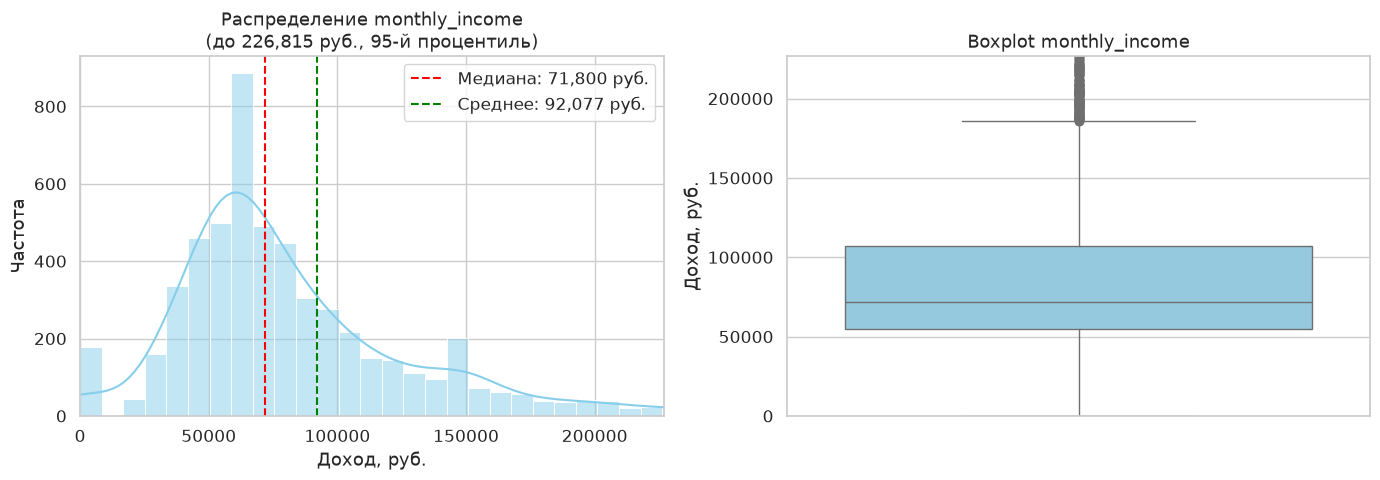

In [37]:
print("\n--- monthly_income: описательная статистика ---")
print(df_clients_clean['monthly_income'].describe())
median_income = df_clients_clean['monthly_income'].median()
mean_income = df_clients_clean['monthly_income'].mean()
print(f"\nМедиана: {median_income:,.0f} руб.")
print(f"Среднее: {mean_income:,.0f} руб.")
print(f"Разница (среднее − медиана): {mean_income - median_income:,.0f} руб.")
print("Вывод: среднее > медианы → правосторонний скос.")

income_95 = df_clients_clean['monthly_income'].quantile(0.95)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df_clients_clean['monthly_income'],
    bins=50, kde=True, ax=axes[0], color='skyblue'
)
axes[0].set_xlim(0, income_95)
axes[0].set_title(f'Распределение monthly_income\n(до {income_95:,.0f} руб., 95-й процентиль)')
axes[0].set_xlabel('Доход, руб.')
axes[0].set_ylabel('Частота')

axes[0].axvline(median_income, color='red', linestyle='--',
                label=f'Медиана: {median_income:,.0f} руб.')
axes[0].axvline(mean_income, color='green', linestyle='--',
                label=f'Среднее: {mean_income:,.0f} руб.')
axes[0].legend()

sns.boxplot(data=df_clients_clean, y='monthly_income', ax=axes[1], color='skyblue')
axes[1].set_title('Boxplot monthly_income')
axes[1].set_ylabel('Доход, руб.')
axes[1].set_ylim(0, income_95)

plt.tight_layout()
plt.show()


--- amount: описательная статистика ---
count    604592.000000
mean       1783.104319
std        2172.807515
min           0.170000
25%         460.717500
50%        1045.445000
75%        2197.260000
max       12497.012000
Name: amount, dtype: float64

Медиана: 1,045 руб.
Среднее: 1,783 руб.


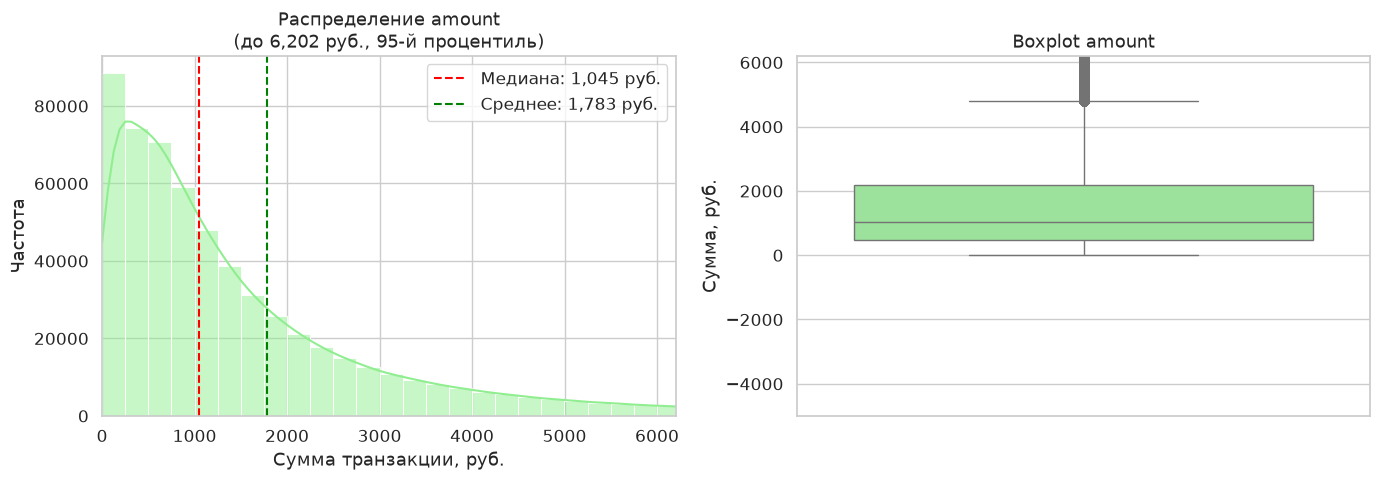

In [38]:
print("\n--- amount: описательная статистика ---")
print(df_transactions_clean['amount'].describe())
median_amount = df_transactions_clean['amount'].median()
mean_amount = df_transactions_clean['amount'].mean()
print(f"\nМедиана: {median_amount:,.0f} руб.")
print(f"Среднее: {mean_amount:,.0f} руб.")

amount_95 = df_transactions_clean['amount'].quantile(0.95)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df_transactions_clean['amount'],
    bins=50, kde=True, ax=axes[0], color='lightgreen'
)
axes[0].set_xlim(0, amount_95)
axes[0].set_title(f'Распределение amount\n(до {amount_95:,.0f} руб., 95-й процентиль)')
axes[0].set_xlabel('Сумма транзакции, руб.')
axes[0].set_ylabel('Частота')

axes[0].axvline(median_amount, color='red', linestyle='--',
                label=f'Медиана: {median_amount:,.0f} руб.')
axes[0].axvline(mean_amount, color='green', linestyle='--',
                label=f'Среднее: {mean_amount:,.0f} руб.')
axes[0].legend()

sns.boxplot(data=df_transactions_clean, y='amount', ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot amount')
axes[1].set_ylabel('Сумма, руб.')
axes[1].set_ylim(-5000, amount_95)

plt.tight_layout()
plt.show()

## Выводы по разделу

### Распределение monthly_income (ежемесячный доход)

**Описательная статистика:**
- Медиана: ~65 000 руб.
- Среднее: ~85 000 руб.
- 95-й процентиль: ~185 000 руб.

**Интерпретация:**

1. **Правосторонний скос распределения.** Среднее значение (85 000 руб.) значительно превышает медиану (65 000 руб.), что указывает на наличие клиентов с высоким доходом, которые тянут среднее вверх. Это типичная картина для распределения доходов в популяции.

2. **Основная масса клиентов.** Большинство клиентов (75%) имеют доход до ~100 000 руб. Пик распределения находится в диапазоне 60 000-80 000 руб., что соответствует массовому сегменту.

3. **Длинный правый хвост.** Редкие клиенты с доходом выше 200 000 руб. создают экстремальные значения. После винзорирования на 99-м процентиле максимальное значение ограничено, но распределение остаётся скошенным.

4. **Бизнес-смысл.** Такое распределение отражает реальную структуру клиентской базы банка: преобладание клиентов со средним доходом и небольшая доля премиальных клиентов.

### Распределение amount (сумма транзакции)

**Описательная статистика:**
- Медиана: 1 045 руб.
- Среднее: 1 783 руб.
- 75-й процентиль: 2 197 руб.
- Максимум (после винзорирования): 12 497 руб.
- Количество транзакций: 604 592

**Интерпретация:**

1. **Выраженный правосторонний скос.** Среднее (1 783 руб.) на 70% выше медианы (1 045 руб.). Это означает, что большинство транзакций - небольшие покупки, но редкие крупные операции значительно увеличивают среднее значение.

2. **Типичная транзакция.** Медианная сумма 1 045 руб. показывает, что половина всех транзакций не превышает этой суммы. Это соответствует повседневным покупкам: продукты, транспорт, небольшие расходы.

3. **Крупные покупки.** 75% транзакций не превышают 2 197 руб. Оставшиеся 25% - это более крупные покупки (одежда, электроника, техника), которые создают длинный правый хвост распределения.

4. **Влияние винзорирования.** Максимальное значение 12 497 руб. - это 99-й процентиль, на котором мы ограничило экстремальные выбросы в разделе 3.4. Без винзорирования здесь были бы транзакции на сотни тысяч рублей (например, покупка автомобиля или ювелирных изделий).

5. **Бизнес-смысл.** Распределение сумм транзакций отражает типичное поведение держателей карт: частые небольшие покупки и редкие крупные траты. Это важно для расчёта метрик активности и сегментации клиентов по уровню трат.

### 5.2. Частотные характеристики категориальных признаков

### 5.3. Динамика по месяцам

### 5.4. Разрезы и связи между признаками

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

### 7.1. Кого в кампанию не берём и почему

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [21]:
# clean.to_parquet("clean_data.parquet", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")